# Classification

## Import des dépendances

In [ ]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

KeyboardInterrupt: 

## Définition de la longueur et de la largeur de l'image

In [ ]:
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

## Chargement des images

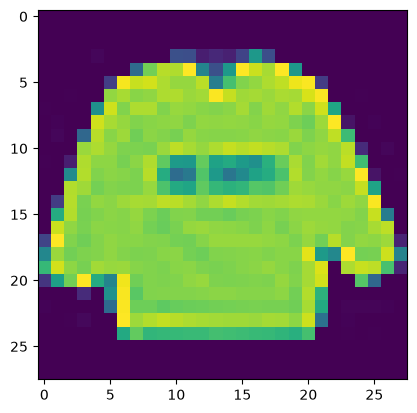

In [ ]:
observations_entrainement = pnd.read_csv('data/fashion-mnist_train.csv')

#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d’apprentissage

### Création des catégories à l'aide de Keras

In [ ]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))

### Répartition des données d'entrainement en données d'apprentissage et données de validation

80% de données d'apprentissage et 20% de données de validation

In [ ]:
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

## Reformater et transformer les données des images
Les données sont au format 28*28 et chaque pixel est transformé afin d'être compris dans une plage de valeurs entre 0 et 1.

In [ ]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(
    X_apprentissage.shape[0],
    LARGEUR_IMAGE, 
    LONGUEUR_IMAGE, 1
)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(
    X_validation.shape[0],
    LARGEUR_IMAGE, 
    LONGUEUR_IMAGE, 1
)

X_validation = X_validation.astype('float32')
X_validation /= 255

## Préparer les données de tests
Les données sont préparées de la même manière que celles d'apprentissage.

In [ ]:
# Préparation des données de tests
observations_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Réseau avec une seule couche de convolution

### Configuration
La configuration de notre premier réseau de neurones à convolution va comporter les éléments suivants:

- Une couche de convolution de 32 filtres de taille 3x3 avec une fonction d’activation de type ReLU
- Un pooling composé d’un filtre de 2x2
- Une phase de flatten (mise en colonne des résultats du pooling)
- Un réseau de neurones complètement connecté de 128 neurones avec une fonction d’activation de type ReLU
- Un dernier réseau de neurones complètement connecté comportant 10 neurones et une fonction d’activation de type Softmax correspondant aux 10 catégories d’images à prédire

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

# 1- Ajout de la couche de convolution comportant
#    - 32 filtres de de taille 3x3 (Kernel) parcourant l'image
#    - Une fonction d'activation de type ReLU (Rectified Linear Activation)
#    - Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(
    Conv2D(
        32, 
        kernel_size=(3, 3), 
        activation='relu'
    )
)

# 2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

# 3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

# 5- On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

# 6- Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

# 7- Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

### Compilation
La compilation se fait en précisant la fonction de minimisation de l'erreur, l'optimiseur (algorithme Adam) et la valeur mesurée (la précision).

In [ ]:
reseauNeurone1Convolution.compile(
    loss=keras.losses.categorical_crossentropy, 
    optimizer=tf.keras.optimizers.Adam(), 
    metrics=['accuracy']
)

### Apprentissage
10 passages complets du jeu de données (epochs), 256 images traitées à la fois (batch_size), validation sur les 20% de données de validation.

In [ ]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8099 - loss: 0.5481 - val_accuracy: 0.8673 - val_loss: 0.3851
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8751 - loss: 0.3543 - val_accuracy: 0.8812 - val_loss: 0.3408
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.8914 - loss: 0.3106 - val_accuracy: 0.8907 - val_loss: 0.3072
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9002 - loss: 0.2834 - val_accuracy: 0.8981 - val_loss: 0.2860
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9050 - loss: 0.2671 - val_accuracy: 0.9013 - val_loss: 0.2793
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9105 - loss: 0.2493 - val_accuracy: 0.8967 - val_loss: 0.2799
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9153 - loss: 0.2348 - val_accuracy: 0.9030 - val_loss: 0.2745
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9189 - loss: 0.2229 - val_accu

### Évaluation du modèle sur les données de tests

In [ ]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.2461920827627182
Précision: 0.9120000004768372


### Courbes de précision et d'erreur

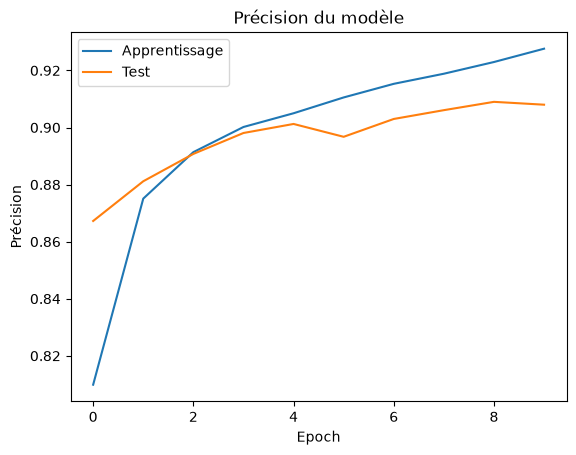

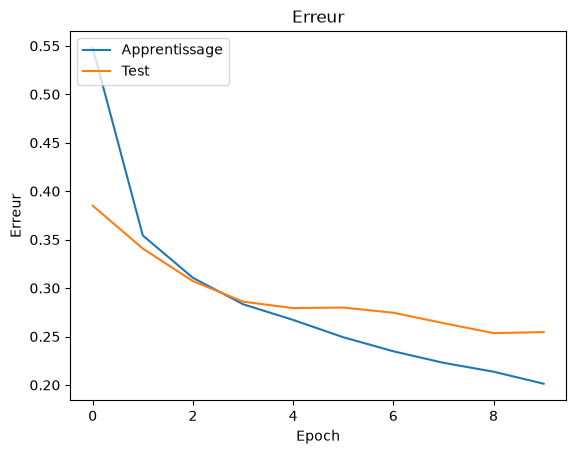

In [ ]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

## Augmentation du nombre de données

### Générateur d'images
Création de nouvelles images par rotation, translation, cisaillement et zoom aléatoires des images d'apprentissage.

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

### Génération des nouvelles images

In [ ]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

### Nouvel apprentissage
50 epochs de 187 itérations (48 000 / 256).

In [ ]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

Epoch 1/50


I0000 00:00:1793647227.403707   60963 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 67ms/step - accuracy: 0.8266 - loss: 0.4660 - val_accuracy: 0.8441 - val_loss: 0.4147
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.8203 - loss: 0.5095

/home/ian/Workspace/School/420-5G4-ML/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8203 - loss: 0.5095 - val_accuracy: 0.8452 - val_loss: 0.4113
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 69ms/step - accuracy: 0.8464 - loss: 0.4093 - val_accuracy: 0.8510 - val_loss: 0.3936
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8867 - loss: 0.3362 - val_accuracy: 0.8533 - val_loss: 0.3913
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8545 - loss: 0.3928 - val_accuracy: 0.8599 - val_loss: 0.3759
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8516 - loss: 0.4011 - val_accuracy: 0.8606 - val_loss: 0.3728
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8614 - loss: 0.3730 - val_accuracy: 0.8658 - val_loss: 0.3685
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8828 - loss: 0.3094 - val_accuracy: 0.8647 - val_loss: 0.3620
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8659 - loss: 0.3633 - val_accuracy: 0

### Évaluation du nouveau modèle sur les données de tests

In [ ]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Erreur : 0.23793147504329681
Précision: 0.9136000275611877


## Sauvegarde du modèle
La définition du modèle est sauvegardée au format JSON et les poids dans un fichier H5, dans le répertoire `modele/`.

In [64]:
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
